# Introduction to Classification — INSTRUCTOR SOLUTION

**How to use this notebook.** The storms questions are discussion questions: each gets a written answer *and* the
code that checks it, so the numbers are on screen. The Titanic questions are answered in five beats: **Approach**
→ **code** (complete and executed) → **What the code does** → **Expected output** → **Common mistakes**.
Everything else is the student notebook, unchanged.

**Links to the topic.** Topic 11.1 defines every score used here from the confusion matrix — accuracy, precision,
recall, F1 for either class, the threshold rule and the precision–recall curve — and computes each by hand before
calling scikit-learn. The formulas are repeated briefly where they are used.

**Two conventions to say out loud.** Scores here are *training* scores, as the questions ask (the models are
scored on the rows they were fitted to, so they flatter). And with $k = 10$ a predicted probability can be
exactly 0.5; scikit-learn's `predict` breaks that tie toward the first class (non-survivor), whereas the rule
"predict survival if $\hat p \ge 0.5$" calls it a survivor — the two give slightly different numbers in
Titanic questions 3–5.

In [1]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [2]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


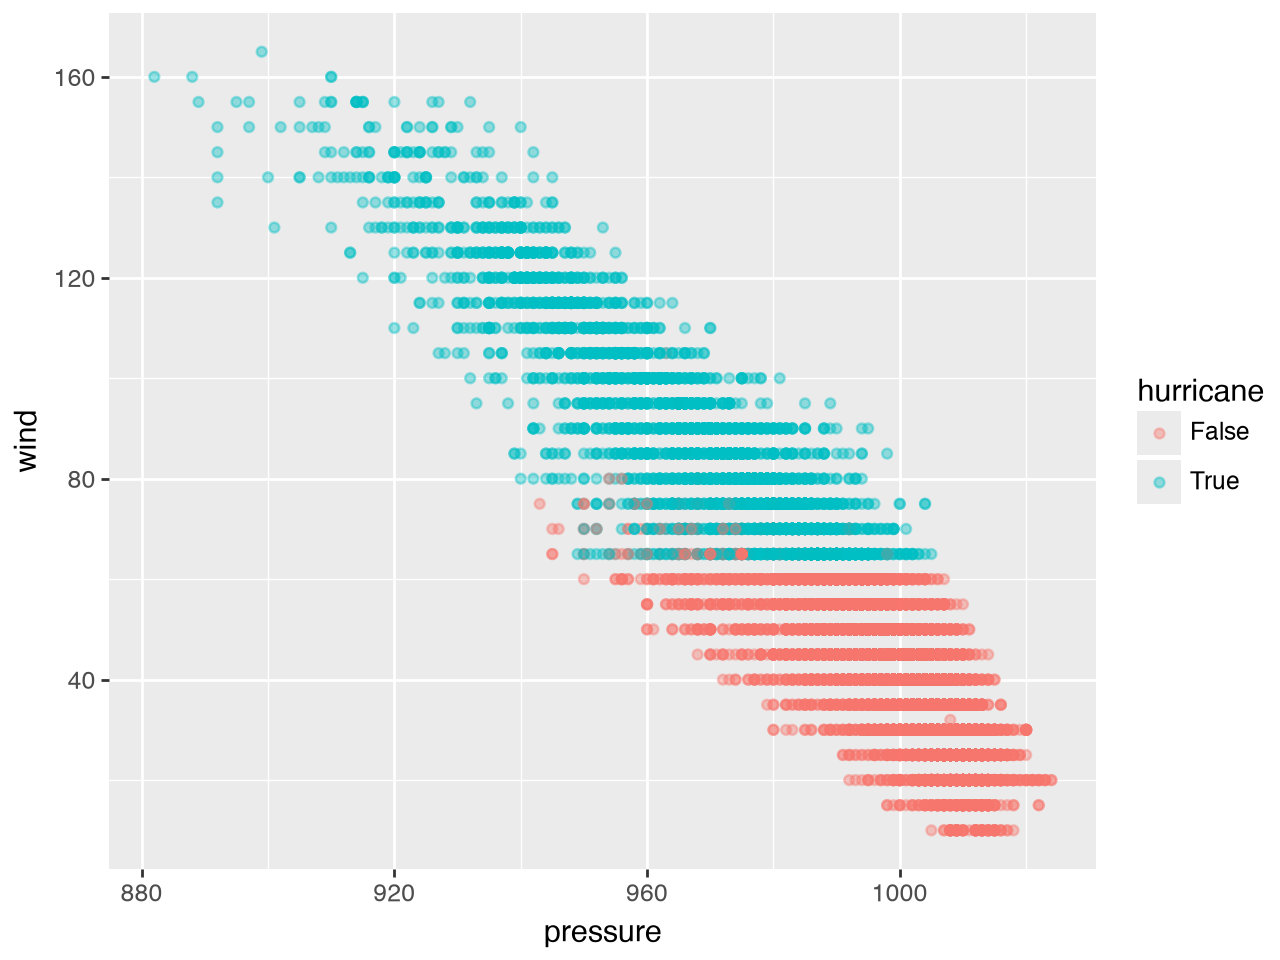

In [3]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

**Answer 1 (a simple rule).** **Predict "hurricane" when wind ≥ 64 knots.** In the plot the hurricane points
occupy the upper-left (high wind, low pressure) and the boundary is almost perfectly horizontal: there are no
hurricanes below about 65 knots, and very few non-hurricanes above it. That is not a coincidence — 64 knots
(74 mph) *is* the definition of a Category 1 hurricane on the Saffir–Simpson scale, so the `status` label was
essentially assigned from wind speed. A pressure rule would do worse: the hurricane and non-hurricane clouds
overlap between roughly 975 and 1000 mb, so any pressure cut-off either misses many hurricanes or sweeps in many
tropical storms.

Why this rule should have both high **precision** (of the records it calls hurricanes, almost all are) and high
**recall** (of the hurricane records, it catches essentially all): the hurricane region is a clean band with a
sharp edge, so one horizontal line separates it with very few points on the wrong side. The check below shows
the rule, and a pressure rule for comparison.

In [4]:
rule_wind = df_storms["wind"] >= 64
rule_pressure = df_storms["pressure"] <= 980
print("hurricane records:", df_storms["hurricane"].sum(), "of", len(df_storms))
print("wind >= 64:     predicted hurricanes", rule_wind.sum(), " of which actual hurricanes", (rule_wind & df_storms["hurricane"]).sum())
print("pressure <= 980: predicted hurricanes", rule_pressure.sum(), " of which actual hurricanes", (rule_pressure & df_storms["hurricane"]).sum())
print("minimum wind among hurricanes:", df_storms.loc[df_storms["hurricane"], "wind"].min(),
      "  maximum wind among non-hurricanes:", df_storms.loc[~df_storms["hurricane"], "wind"].max())

hurricane records: 4684 of 19066
wind >= 64:     predicted hurricanes 4812  of which actual hurricanes 4684
pressure <= 980: predicted hurricanes 3690  of which actual hurricanes 3204
minimum wind among hurricanes: 65   maximum wind among non-hurricanes: 105


2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

### Solution 2 — the scores of the rule, by counting

**Approach.** Make the predictions with the rule, count the four cells of the confusion matrix (positive class =
hurricane), then compute every score as a ratio of counts. scikit-learn's functions are called alongside to
confirm; `pos_label=False` gives the non-hurricane versions (e and f are the same question — precision then
recall — for the non-hurricane class).

In [5]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

actual = df_storms["hurricane"]                 # True = hurricane (the positive class)
predicted = df_storms["wind"] >= 64             # the rule from question 1

cm = confusion_matrix(actual, predicted, labels=[True, False])   # rows: actual hurricane / not; columns: predicted hurricane / not
TP, FN, FP, TN = cm.ravel()
n = len(actual)
print(pd.DataFrame(cm, index=["actual hurricane", "actual non-hurricane"], columns=["predicted hurricane", "predicted non-hurricane"]))
print(f"\nTP = {TP}   FN = {FN}   FP = {FP}   TN = {TN}   n = {n}")

                      predicted hurricane  predicted non-hurricane
actual hurricane                     4684                        0
actual non-hurricane                  128                    14254

TP = 4684   FN = 0   FP = 128   TN = 14254   n = 19066


In [6]:
scores = pd.DataFrame({
    "formula": ["(TP + TN) / n", "TP / (TP + FP)", "TP / (TP + FN)", "2TP / (2TP + FP + FN)",
                "TN / (TN + FN)", "TN / (TN + FP)", "2TN / (2TN + FN + FP)"],
    "by hand": [(TP + TN) / n, TP / (TP + FP), TP / (TP + FN), 2 * TP / (2 * TP + FP + FN),
                TN / (TN + FN), TN / (TN + FP), 2 * TN / (2 * TN + FN + FP)],
    "scikit-learn": [accuracy_score(actual, predicted),
                     precision_score(actual, predicted), recall_score(actual, predicted), f1_score(actual, predicted),
                     precision_score(actual, predicted, pos_label=False), recall_score(actual, predicted, pos_label=False),
                     f1_score(actual, predicted, pos_label=False)],
}, index=["a. accuracy", "b. precision (hurricane)", "c. recall (hurricane)", "d. F1 (hurricane)",
          "e. precision (non-hurricane)", "f. recall (non-hurricane)", "g. F1 (non-hurricane)"])
scores.round(4)

,formula,by hand,scikit-learn
a. accuracy,(TP + TN) / n,0.9933,0.9933
b. precision (hurricane),TP / (TP + FP),0.9734,0.9734
c. recall (hurricane),TP / (TP + FN),1.0000,1.0000
d. F1 (hurricane),2TP / (2TP + FP + FN),0.9865,0.9865
e. precision (non-hurricane),TN / (TN + FN),1.0000,1.0000
f. recall (non-hurricane),TN / (TN + FP),0.9911,0.9911
g. F1 (non-hurricane),2TN / (2TN + FN + FP),0.9955,0.9955


**Answer 2 (interpretations, in context).** The rule "wind ≥ 64 knots" applied to the 19,066 storm records:

- **a. Accuracy 99.33 %** — 99.33 % of all storm records are classified correctly by the rule (18,938 of 19,066).
- **b. Precision for hurricanes 97.34 %** — of the 4,812 records the rule calls hurricanes, 97.34 % really are
  hurricanes; the other 128 are mostly *extratropical* systems with hurricane-force winds that the data set does
  not label as hurricanes.
- **c. Recall for hurricanes 100 %** — of the 4,684 hurricane records, the rule catches every one: no hurricane has
  wind below 64 knots.
- **d. F1 for hurricanes 98.65 %** — the harmonic mean of 97.34 % and 100 %, a single summary that both the false
  alarms and the (zero) misses feed into: $2(4684)/(2 \cdot 4684 + 128 + 0)$.
- **e. Precision for non-hurricanes 100 %** — of the 14,254 records the rule calls non-hurricanes, 100 % are
  non-hurricanes (because the rule never misses a hurricane, it never puts one in this group).
- **f. Recall for non-hurricanes 99.11 %** — of the 14,382 non-hurricane records, 99.11 % are correctly left as
  non-hurricanes; the 128 extratropical records with winds of 64 knots or more are the exceptions.
- **g. F1 for non-hurricanes 99.55 %** — the harmonic mean of 100 % and 99.11 %.

The two classes' scores are mirror images of the same two cells: the 128 false alarms lower hurricane precision
*and* non-hurricane recall; the zero misses give hurricane recall of 1 *and* non-hurricane precision of 1.

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

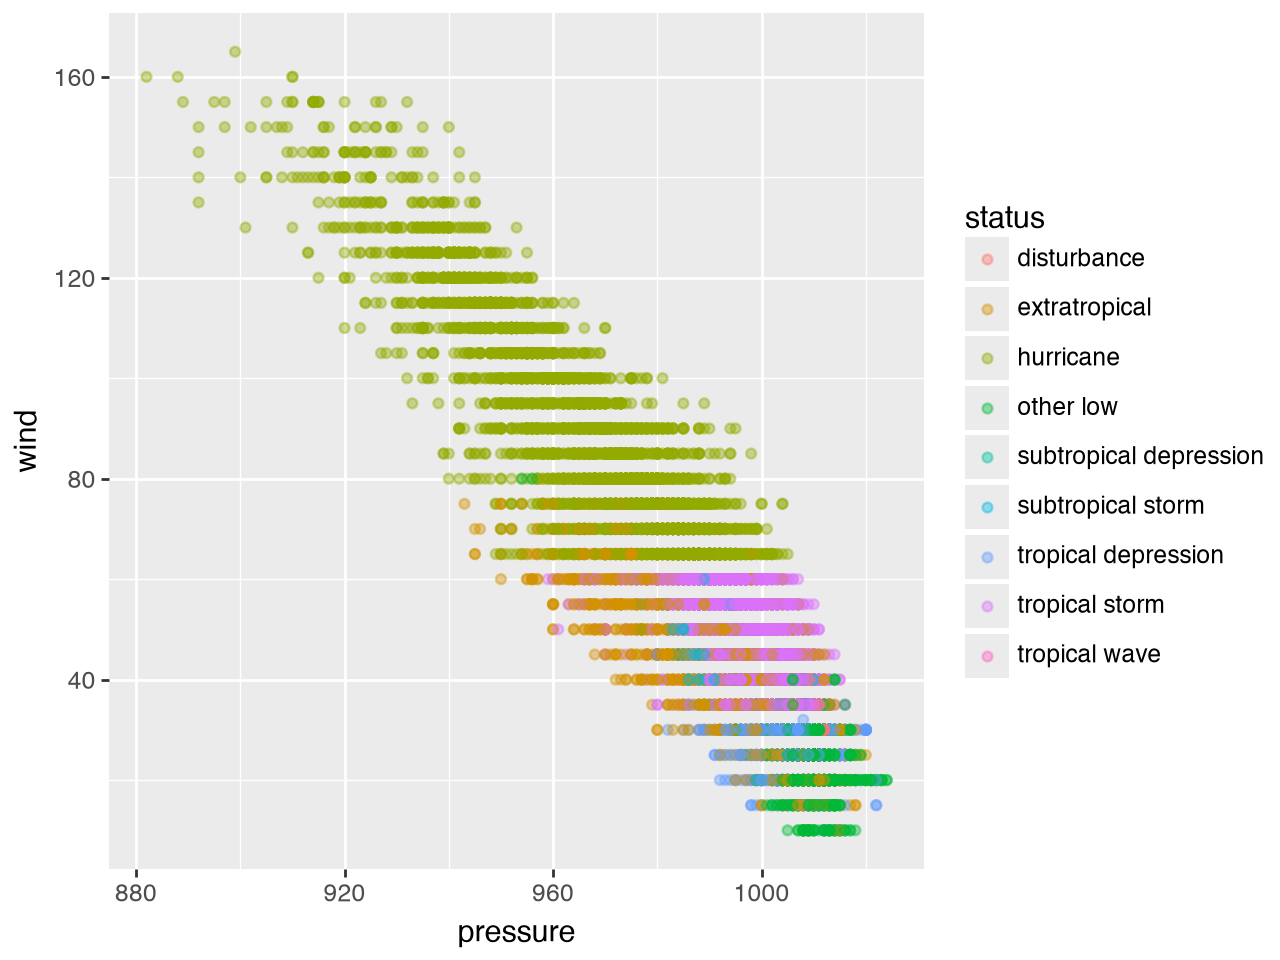

In [7]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

**Answer 3 (10-NN at pressure 975, wind 39).** The model would predict **extratropical**. A storm at 975 mb
with only 39 knots of wind sits in an odd corner of the plot: pressure that low usually goes with hurricane-force
wind, while 39-knot storms are usually near 1000 mb. The only status that lives in that corner — low pressure
with modest wind — is **extratropical** (storms that have moved out of the tropics and spread out, keeping low
pressure but losing wind). Tropical storms at 39 knots cluster around 995–1005 mb, so the ten nearest records are
extratropical ones around 973–978 mb and 40 knots, and the vote is nine or ten to zero. The superimposed points
matter: there are many identical (wind, pressure) rows in the data, so the ten nearest can all be copies of the
same two or three combinations.

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn_status = KNeighborsClassifier(n_neighbors=10).fit(df_storms[["wind", "pressure"]], df_storms["status"])
query = pd.DataFrame({"wind": [39], "pressure": [975]})
print("prediction:", knn_status.predict(query)[0])
print("vote shares:", {c: p for c, p in zip(knn_status.classes_, knn_status.predict_proba(query)[0]) if p > 0})

distances, idx = knn_status.kneighbors(query)
df_storms.iloc[idx[0]][["wind", "pressure", "status"]].assign(distance=distances[0].round(2))

prediction: extratropical
vote shares: {'extratropical': np.float64(0.9), 'tropical storm': np.float64(0.1)}


,wind,pressure,status,distance
17609,40,976,extratropical,1.41
18989,40,976,extratropical,1.41
3540,40,974,extratropical,1.41
17608,40,974,extratropical,1.41
5763,40,977,extratropical,2.24
18163,40,977,extratropical,2.24
17147,40,977,extratropical,2.24
17146,40,973,extratropical,2.24
6650,40,977,extratropical,2.24
10412,40,978,tropical storm,3.16


4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

**Answer 4 (lowest recall).** The classes with the **lowest recall** will be the rare statuses whose points sit on
top of a common class: **tropical wave**, **disturbance**, **subtropical storm** and **subtropical depression**,
with **other low** not far behind. Recall for a class is the share of its records the model gets right, and a
10-NN vote is decided by whoever has the most records nearby. A tropical wave at 30 knots and 1010 mb is
surrounded by hundreds of tropical depressions with the same wind and pressure, so it is outvoted every time; a
subtropical storm at 45 knots and 1000 mb is outvoted by tropical storms. **Hurricane** and **tropical storm**,
the big classes with their own territory, will have the highest recall; **extratropical** is in between (it owns
the low-pressure/low-wind corner but overlaps tropical storms elsewhere). The report confirms it: four classes
have recall at or near zero.

In [9]:
from sklearn.metrics import classification_report

print(classification_report(df_storms["status"], knn_status.predict(df_storms[["wind", "pressure"]]), zero_division=0, digits=2))

                        precision    recall  f1-score   support

           disturbance       0.00      0.00      0.00       146
         extratropical       0.60      0.37      0.45      2068
             hurricane       0.98      0.99      0.99      4684
             other low       0.68      0.08      0.14      1405
subtropical depression       0.06      0.13      0.08       151
     subtropical storm       0.00      0.00      0.00       292
   tropical depression       0.63      0.90      0.74      3525
        tropical storm       0.84      0.95      0.89      6684
         tropical wave       0.00      0.00      0.00       111

              accuracy                           0.79     19066
             macro avg       0.42      0.38      0.37     19066
          weighted avg       0.77      0.79      0.75     19066



## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [10]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

### Solution 1 — a 10-nearest-neighbor survival model

**Approach.** Three features of two kinds: `age` is numeric and is scaled (KNN measures distance); `gender` and
`class` are categorical and are one-hot encoded. A `ColumnTransformer` routes each column, a `Pipeline` attaches
the `KNeighborsClassifier(n_neighbors=10)`, and `.fit` on all 2,205 people with a known age — the question asks
for a training model. Note that `class` has seven levels, including the crew departments.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

features = ["age", "gender", "class"]
X_titanic = df_titanic[features]
y_titanic = df_titanic["survived"]            # 1 = survived, 0 = did not
print(df_titanic["class"].value_counts().to_dict())

preprocessing = ColumnTransformer([
    ("scale",   StandardScaler(), ["age"]),
    ("dummify", OneHotEncoder(), ["gender", "class"]),
])
knn_titanic = Pipeline([("preprocessing", preprocessing),
                        ("knn", KNeighborsClassifier(n_neighbors=10))])
knn_titanic.fit(X_titanic, y_titanic)
print("classes_:", knn_titanic["knn"].classes_, "   survivors in the data:", y_titanic.sum(), "of", len(y_titanic))

{'3rd': 707, 'victualling crew': 431, '1st': 324, 'engineering crew': 324, '2nd': 284, 'restaurant staff': 69, 'deck crew': 66}
classes_: [0 1]    survivors in the data: 711 of 2205


**What the code does.** The transformer produces one scaled column plus 2 + 7 dummy columns; distances are
measured in that 10-dimensional space; `fit` stores the rows. `classes_` is `[0, 1]`, so column 1 of
`predict_proba` will be P(survived).

**Expected output.** A fitted pipeline; 711 survivors among 2,205 people (32 %). Nothing to interpret yet.

**Common mistakes.** Forgetting to scale `age` (then a 20-year age gap counts as much as twenty dummy flips and
gender barely matters); passing `survived` as text; dropping the crew classes because they "aren't passengers" —
the question says "passenger", but the data set and the later questions use everyone.

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

### Solution 2 — two 20-year-old women

**Approach.** Build a two-row DataFrame with the same column names, call `predict` for the labels and
`predict_proba` for the vote shares.

In [12]:
new_people = pd.DataFrame({"age": [20, 20], "gender": ["female", "female"], "class": ["1st", "3rd"]})
new_people["predicted"] = knn_titanic.predict(new_people)
new_people["P(survived)"] = knn_titanic.predict_proba(new_people)[:, 1]
new_people

,age,gender,class,predicted,P(survived)
0,20,female,1st,1,1.0
1,20,female,3rd,0,0.2


**What the code does.** For each new person the model finds the 10 nearest training people in the scaled-and-
dummified space and reports the share who survived.

**Expected output.** The 20-year-old woman in **first class is predicted to survive**, with predicted probability
**1.0** — all ten of her nearest neighbors (young first-class women) survived. The 20-year-old woman in **third
class is predicted not to survive**, with predicted probability of survival **0.2**: only two of her ten nearest
neighbors survived. Same age, same sex; the class dummies move the query to a different neighborhood of the
training data.

**Common mistakes.** Reading `predict_proba(...)[:, 0]` as P(survived) — column 0 is P(did not survive);
spelling the class `"first"` or `1` so the encoder sees an unknown category (with the default
`handle_unknown="error"` this raises; the exact strings are `"1st"`, `"3rd"`).

3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

### Solution 3 — training precision, recall and F1 for survivors

**Approach.** Predict every training row, build the confusion matrix with survived = positive, compute the three
scores as ratios of its cells, and confirm with scikit-learn.

In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

pred_titanic = knn_titanic.predict(X_titanic)
prob_survive = knn_titanic.predict_proba(X_titanic)[:, 1]

cm_t = confusion_matrix(y_titanic, pred_titanic)         # rows actual 0, 1; columns predicted 0, 1
TN, FP, FN, TP = cm_t.ravel()
print(pd.DataFrame(cm_t, index=["actual died", "actual survived"], columns=["predicted died", "predicted survived"]))
print(f"\nsurvivors as positive:  TP = {TP}  FP = {FP}  FN = {FN}  TN = {TN}")
print(f"precision = {TP}/({TP}+{FP}) = {TP/(TP+FP):.4f}   sklearn {precision_score(y_titanic, pred_titanic):.4f}")
print(f"recall    = {TP}/({TP}+{FN}) = {TP/(TP+FN):.4f}   sklearn {recall_score(y_titanic, pred_titanic):.4f}")
print(f"F1        = 2*{TP}/(2*{TP}+{FP}+{FN}) = {2*TP/(2*TP+FP+FN):.4f}   sklearn {f1_score(y_titanic, pred_titanic):.4f}")
print(f"(accuracy {accuracy_score(y_titanic, pred_titanic):.4f}; baseline 'everyone dies' {1 - y_titanic.mean():.4f})")

                 predicted died  predicted survived
actual died                1427                  67
actual survived             332                 379

survivors as positive:  TP = 379  FP = 67  FN = 332  TN = 1427
precision = 379/(379+67) = 0.8498   sklearn 0.8498
recall    = 379/(379+332) = 0.5331   sklearn 0.5331
F1        = 2*379/(2*379+67+332) = 0.6551   sklearn 0.6551
(accuracy 0.8190; baseline 'everyone dies' 0.6776)


**What the code does.** `predict` applies the default rule (the more common class among the 10 neighbors, with
5–5 ties going to class 0); the rest is counting.

**Expected output and interpretation.** TP = 379, FP = 67, FN = 332, TN = 1,427.

- **Precision ≈ 0.850**: of the 446 people the model predicts to survive, 85 % actually survived.
- **Recall ≈ 0.533**: of the 711 actual survivors, the model identifies only 53 % — it misses almost half of them,
  mostly men and third-class passengers who survived against the odds of their group.
- **F1 ≈ 0.655**: the harmonic mean, pulled down toward the weak recall.

The model is cautious about predicting survival: when it does, it is usually right, but it fails to flag many
survivors. Accuracy (0.819) looks better than the baseline (0.678) but hides this asymmetry.

**Common mistakes.** Reporting the scores for the wrong class (precision_score defaults to `pos_label=1`, which
is survivors here, but only because survival is coded 1); reading the confusion matrix with rows and columns
swapped; computing "recall" as TP/(TP + FP).

4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

### Solution 4 — the same scores for non-survivors

**Approach.** Same predictions, the other class as positive: `pos_label=0`. In confusion-matrix terms the roles
of the cells swap — the non-survivor "true positives" are the TN cell above.

In [14]:
print(f"precision (non-survivors) = TN/(TN+FN) = {TN}/({TN}+{FN}) = {TN/(TN+FN):.4f}   sklearn {precision_score(y_titanic, pred_titanic, pos_label=0):.4f}")
print(f"recall    (non-survivors) = TN/(TN+FP) = {TN}/({TN}+{FP}) = {TN/(TN+FP):.4f}   sklearn {recall_score(y_titanic, pred_titanic, pos_label=0):.4f}")
print(f"F1        (non-survivors) = 2TN/(2TN+FN+FP) = {2*TN/(2*TN+FN+FP):.4f}   sklearn {f1_score(y_titanic, pred_titanic, pos_label=0):.4f}")

precision (non-survivors) = TN/(TN+FN) = 1427/(1427+332) = 0.8113   sklearn 0.8113
recall    (non-survivors) = TN/(TN+FP) = 1427/(1427+67) = 0.9552   sklearn 0.9552
F1        (non-survivors) = 2TN/(2TN+FN+FP) = 0.8773   sklearn 0.8773


**What the code does.** `pos_label=0` tells each scorer to treat 0 (did not survive) as the class of interest.

**Expected output and interpretation.**

- **Precision ≈ 0.811**: of the 1,759 people the model predicts to die, 81 % did — the 332 missed survivors are
  in this group and drag it down.
- **Recall ≈ 0.955**: of the 1,494 people who died, the model identifies 96 %; only 67 are wrongly predicted to
  survive.
- **F1 ≈ 0.877**.

Compared with question 3: the model is good at *catching* non-survivors (high recall) and good at *trusting* a
survival prediction (high survivor precision); its weakness is the 332 survivors it predicts to die, which show
up as low survivor recall *and* lowered non-survivor precision — one set of errors, two scores.

**Common mistakes.** Recomputing the model instead of re-labelling the positive class; mixing up which class
`pos_label=0` refers to; expecting the two classes' F1 scores to be similar (they need not be — they weigh
different cells).

5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

### Solution 5 — raising the threshold to 0.8

**Approach.** Keep the probabilities from question 3 and change only the decision rule: predict survival when
P(survived) ≥ 0.8 (at least 8 of the 10 neighbors survived). Recompute precision and recall for both classes and
set them next to the threshold-0.5 values. For a fair comparison the 0.5 row uses the same kind of rule,
`prob >= 0.5`, which differs from `predict()` on the 5–5 ties.

In [15]:
def scores_at(threshold):
    pred_t = (prob_survive >= threshold).astype(int)
    return {"threshold": threshold,
            "predicted survivors": pred_t.sum(),
            "precision (survivors)": precision_score(y_titanic, pred_t),
            "recall (survivors)": recall_score(y_titanic, pred_t),
            "precision (non-survivors)": precision_score(y_titanic, pred_t, pos_label=0),
            "recall (non-survivors)": recall_score(y_titanic, pred_t, pos_label=0)}

pd.DataFrame([scores_at(0.5), scores_at(0.8)]).set_index("threshold").round(3)

,predicted survivors,precision (survivors),recall (survivors),precision (non-survivors),recall (non-survivors)
threshold,,,,,
0.5,565,0.781,0.620,0.835,0.917
0.8,321,0.919,0.415,0.779,0.983


In [16]:
print("people with P(survived) exactly 0.5:", (prob_survive == 0.5).sum(),
      "-> predict() calls them non-survivors; the rule 'prob >= 0.5' calls them survivors")

people with P(survived) exactly 0.5: 119 -> predict() calls them non-survivors; the rule 'prob >= 0.5' calls them survivors


**What the code does.** `(prob_survive >= threshold)` is the whole classifier at a new operating point; the four
scores are then counted as before.

**Expected output.** At threshold 0.8 the model predicts survival for only 321 people (instead of 565 at
0.5):

| | threshold 0.5 (rule ≥ 0.5) | threshold 0.8 |
|---|---|---|
| precision, survivors | ≈ 0.78 | **≈ 0.92** ↑ |
| recall, survivors | ≈ 0.62 | **≈ 0.41** ↓ |
| precision, non-survivors | ≈ 0.84 | ≈ 0.78 ↓ |
| recall, non-survivors | ≈ 0.92 | **≈ 0.98** ↑ |

Raising the threshold makes the model demand stronger evidence before calling someone a survivor. So **survivor
precision rises** (the survivors it still names are almost all real) while **survivor recall falls** (it now
misses nearly 60 % of them). The non-survivor class moves the opposite way: its **recall rises** (almost nobody
who died is predicted to survive) and its **precision falls** (the predicted-dead group now contains 416
survivors). The threshold trades one class's recall for the other's — it cannot improve everything at once.

(The 0.5 row here is not identical to questions 3–4 because 119 people have P(survived) exactly 0.5; `predict()`
calls them non-survivors, the ≥ 0.5 rule calls them survivors. Either convention is fine if stated.)

**Common mistakes.** Thresholding the *labels* instead of the probabilities; applying the threshold to column 0;
expecting precision and recall of the same class to move together.

6\. Plot the precision-recall curve for the survivors. Interpret what you see.

### Solution 6 — precision–recall curve for survivors

**Approach.** `precision_recall_curve(y, prob)` evaluates the rule "survivor if $\hat p \ge t$" at every distinct
probability $t$ — with $k = 10$ there are at most eleven: 0, 0.1, …, 1 — and returns precision and recall at
each, plus a final point (recall 0, precision 1). Plot recall on the x-axis, precision on the y-axis, and mark
the no-information level, the survivor share 0.32.

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

prec, rec, thresholds = precision_recall_curve(y_titanic, prob_survive)
curve = pd.DataFrame({"threshold": np.append(thresholds, np.nan), "precision": prec, "recall": rec}).round(3)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(rec, prec, marker="o")
for t_, p_, r_ in zip(thresholds, prec, rec):
    ax.annotate(f"{t_:.1f}", (r_, p_), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(y_titanic.mean(), color="grey", linestyle="--", label=f"no information: precision = survivor share {y_titanic.mean():.2f}")
ax.set_xlabel("recall (share of survivors identified)"); ax.set_ylabel("precision (share of predicted survivors who survived)")
ax.set_title(f"Precision-recall curve, survivors (AP = {average_precision_score(y_titanic, prob_survive):.3f})"); ax.legend(loc="lower left")
curve

,threshold,precision,recall
0,0.0,0.322,1.000
1,0.1,0.388,0.997
2,0.2,0.482,0.917
3,0.3,0.570,0.820
4,0.4,0.704,0.684
5,0.5,0.781,0.620
6,0.6,0.850,0.533
7,0.7,0.896,0.473
8,0.8,0.919,0.415
9,0.9,0.952,0.338


**What the code does.** Each labelled point is one threshold; moving along the curve from right to left raises
the threshold. The annotation shows which threshold produced each point; the table is the same information.

**Expected output and interpretation.** The curve starts at the bottom right — threshold 0, everyone predicted
to survive, recall 1 and precision 0.32 (the survivor share) — and climbs to the top left as the threshold rises:
at 0.5 recall ≈ 0.62 and precision ≈ 0.78, at 0.8 recall ≈ 0.41 and precision ≈ 0.92, at 1.0 (all ten neighbors
survived) recall ≈ 0.21 and precision 1.0. The steady climb says the model ranks people sensibly — the people it
is most confident about really did survive at a very high rate — but there is no threshold with *both* high
precision and high recall: recall above 0.8 costs precision below 0.6. The curve sits well above the dashed
no-information line everywhere, so the model is informative at every operating point; average precision ≈ 0.77
summarizes that.

**Common mistakes.** Plotting precision on the x-axis; passing the predicted labels instead of probabilities (the
curve collapses to one point); forgetting that the last (recall 0, precision 1) point is an artificial endpoint
with no threshold.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

### Solution 7 — precision–recall curve for non-survivors

**Approach.** Same function with the roles reversed: the "positive" class is now death, so pass `1 - y` as the
labels and `1 - prob_survive` = P(did not survive) as the scores. The no-information level is the non-survivor
share, 0.68.

In [18]:
prob_die = 1 - prob_survive
prec0, rec0, thresholds0 = precision_recall_curve(1 - y_titanic, prob_die)
curve0 = pd.DataFrame({"threshold on P(died)": np.append(thresholds0, np.nan), "precision": prec0, "recall": rec0}).round(3)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(rec0, prec0, marker="o")
for t_, p_, r_ in zip(thresholds0, prec0, rec0):
    ax.annotate(f"{t_:.1f}", (r_, p_), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(1 - y_titanic.mean(), color="grey", linestyle="--", label=f"no information: precision = non-survivor share {1 - y_titanic.mean():.2f}")
ax.set_xlabel("recall (share of non-survivors identified)"); ax.set_ylabel("precision (share of predicted non-survivors who died)")
ax.set_title(f"Precision-recall curve, non-survivors (AP = {average_precision_score(1 - y_titanic, prob_die):.3f})"); ax.legend(loc="lower left")
curve0

,threshold on P(died),precision,recall
0,0.0,0.678,1.000
1,0.1,0.727,1.000
2,0.2,0.759,0.992
3,0.3,0.779,0.983
4,0.4,0.795,0.974
5,0.5,0.811,0.955
6,0.6,0.835,0.917
7,0.7,0.851,0.863
8,0.8,0.892,0.705
9,0.9,0.931,0.530


**What the code does.** Identical machinery; only the definition of "positive" changed. A threshold of $t$ on
P(died) is the same decision as a threshold of $1 - t$ on P(survived), so this curve is the other class's view
of the same eleven operating points.

**Expected output and interpretation.** The curve starts at recall 1, precision 0.68 (everyone predicted to die)
and rises far more gently than the survivor curve: at threshold 0.5 on P(died) recall ≈ 0.96 and precision ≈
0.81; at 0.8, recall ≈ 0.71 and precision ≈ 0.89; precision only approaches 1 when all ten neighbors died, where
recall is down to 0.25. Two things to notice. First, the baseline is already high (68 % of people died), so the
model has less room to add precision for this class — the curve hugs a higher floor but climbs less. Second, the
two curves are the same errors seen from two sides: the 332 survivors that the survivor curve counts as misses at
threshold 0.5 are false alarms here, holding non-survivor precision near 0.8 across most of the curve. Non-survival
is the easier class to *catch* (high recall at ordinary thresholds) and the harder class to be *certain* about.

**Common mistakes.** Passing `prob_survive` with `1 - y` (the curve comes out below the baseline); reading a
high recall for non-survivors as a good model overall when it mostly reflects the 68 % base rate; comparing the
two curves' average precisions without noting that their baselines differ (0.68 vs 0.32).